# MAP Matematica 6: Parte 2, FFT y filtros de imagen (nucleo)
**Responsable:** Tony (B). **Incisos:** 1 (pasa bajas), 2 (pasa altas) y 3 (Blur Detection).

El codigo de la FFT esta en `src/fft_nucleo.py` (unica fuente). Este notebook solo lo usa, lo prueba y genera las figuras para el reporte en `reporte/figuras/`.

**Convencion de frecuencia de corte (declararla en el reporte):** radio normalizado `r` en [0, 1] medido desde el centro del espectro centrado. `r = 0` es la frecuencia cero y `r = 1` es la esquina (frecuencia mas alta). Pasa bajas: se conserva `r <= fc`. Pasa altas: se conserva `r > fc`.

In [1]:
# @INCLUIR: src/fft_nucleo.py
# (en el notebook final, la herramienta de union reemplaza esta celda por el codigo de src/fft_nucleo.py)
# ruta de la carpeta con el nucleo de la FFT
import sys
sys.path.append("../src")
# importacion de todas las funciones del nucleo
from fft_nucleo import *

In [2]:
# librerias para graficar
import numpy as np
import matplotlib.pyplot as plt
# carpeta con las imagenes del proyecto y carpeta de salida de figuras del reporte
CARPETA_IMAGENES = Path("../imagenes")
CARPETA_FIGURAS = Path("../reporte/figuras")
# se crea la carpeta de figuras si no existe
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
# tamano al que se ajustan las imagenes (potencia de 2, requisito de la FFT recursiva)
TAM = 256

## 0. Pruebas del nucleo
La FFT propia debe coincidir con `np.fft` (que se usa **solo aqui**, para comparar).

In [3]:
# generador aleatorio con semilla fija para que las pruebas sean repetibles
rng = np.random.default_rng(0)
# prueba de la FFT 1D y su inversa con varias longitudes (todas potencias de 2)
for N in [1, 2, 8, 64, 1024]:
    # senal compleja aleatoria de longitud N
    x = rng.normal(size=N) + 1j * rng.normal(size=N)
    # la FFT propia debe coincidir con la de NumPy
    assert np.allclose(fft_recursiva(x), np.fft.fft(x)), f"FFT 1D falla con N={N}"
    # la inversa debe devolver la senal original
    assert np.allclose(ifft_recursiva(fft_recursiva(x)), x), f"IFFT falla con N={N}"
# la DFT directa (formula del enunciado) tambien debe coincidir
assert np.allclose(dft_directa(x[:64]), np.fft.fft(x[:64])), "DFT directa falla"
# prueba de la FFT 2D con imagen cuadrada y con imagen rectangular
for forma in [(64, 64), (32, 128), (256, 256)]:
    # imagen aleatoria
    img_t = rng.random(forma)
    # comparacion con NumPy
    assert np.allclose(fft2_recursiva(img_t), np.fft.fft2(img_t)), f"FFT 2D falla con {forma}"
    # FFT seguida de inversa debe devolver la imagen
    assert np.allclose(ifft2_recursiva(fft2_recursiva(img_t)).real, img_t), f"IFFT 2D falla con {forma}"
# un pasa bajas con fc = 1.0 debe dejar la imagen intacta
prueba = imagen_sintetica(TAM)
assert np.allclose(filtro_pasabajas(prueba, 1.0), prueba), "pasa bajas con fc=1 deberia ser identidad"
# una longitud que no es potencia de 2 debe producir un error claro
try:
    fft_recursiva(np.zeros(6))
    raise AssertionError("debio fallar con N=6")
except ValueError:
    pass
# mensaje de exito
print("Todas las pruebas del nucleo pasaron")

Todas las pruebas del nucleo pasaron


## Carga de imagenes
Coloque las imagenes del proyecto en `imagenes/`. Si la carpeta esta vacia se usa una imagen sintetica de respaldo (con bordes y texturas) para poder probar todo.

In [4]:
# lista de imagenes que hay en la carpeta del proyecto
rutas = listar_imagenes(CARPETA_IMAGENES)
# si hay imagenes se cargan en gris y ajustadas a TAM x TAM
if rutas:
    imagenes = {r.stem: cargar_imagen(r, TAM) for r in rutas}
# si no hay imagenes se usa la sintetica
else:
    imagenes = {"sintetica": imagen_sintetica(TAM)}
    print("AVISO: no hay imagenes en ../imagenes, se usa la imagen sintetica de respaldo")
# resumen de lo cargado
print("Imagenes a procesar:", list(imagenes))

Imagenes a procesar: ['img1', 'img3', 'img4']


## Inciso 1. Filtro pasa bajas (fc = 0.22, 0.15, 0.96)

--- img1: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  98.41 |     23.44
  0.15 |                  97.40 |     21.28
  0.96 |                 100.00 |     71.98


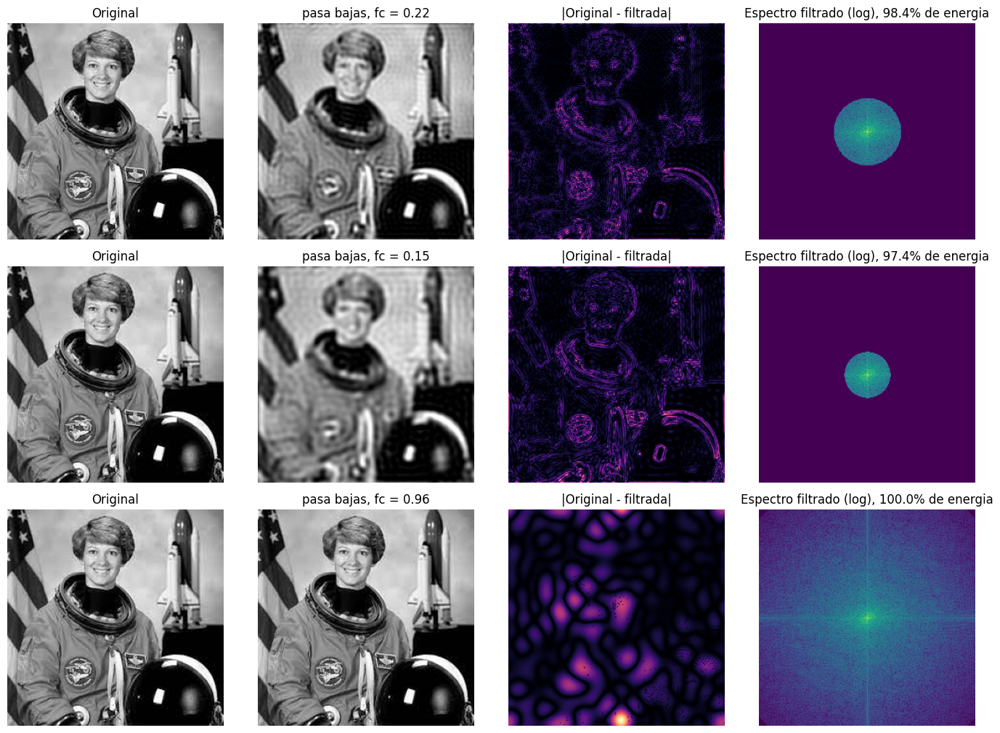

--- img3: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  99.35 |     26.55
  0.15 |                  98.89 |     24.22
  0.96 |                 100.00 |     69.41


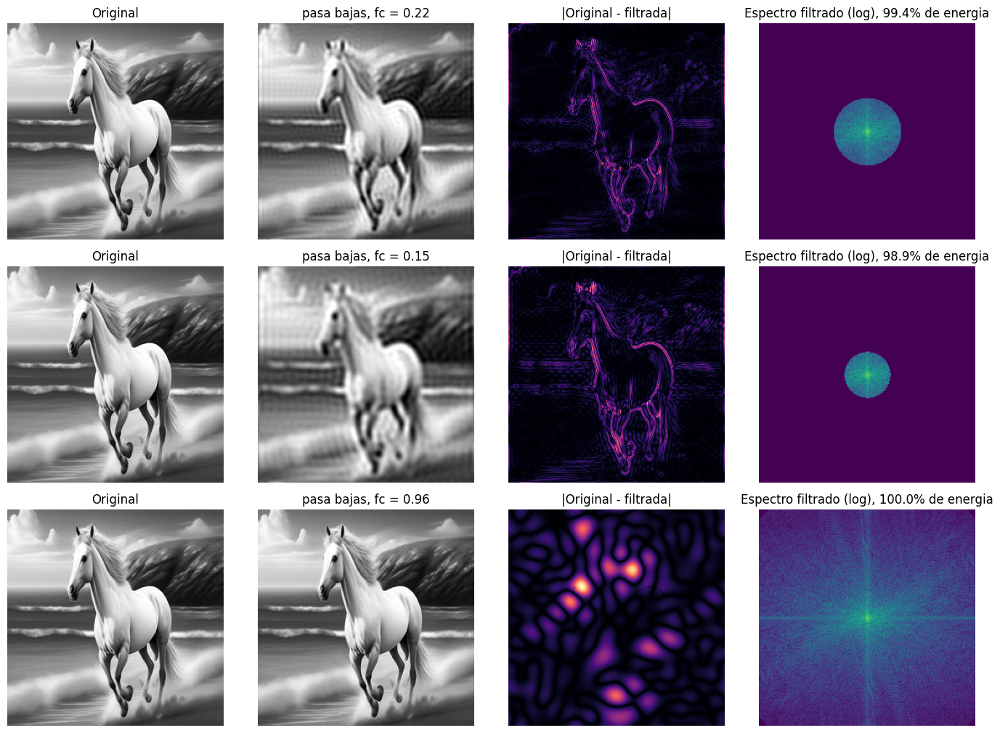

--- img4: pasa bajas ---
    fc | energia conservada (%) | PSNR (dB)
  0.22 |                  98.53 |     25.21
  0.15 |                  97.72 |     23.31
  0.96 |                 100.00 |     68.82


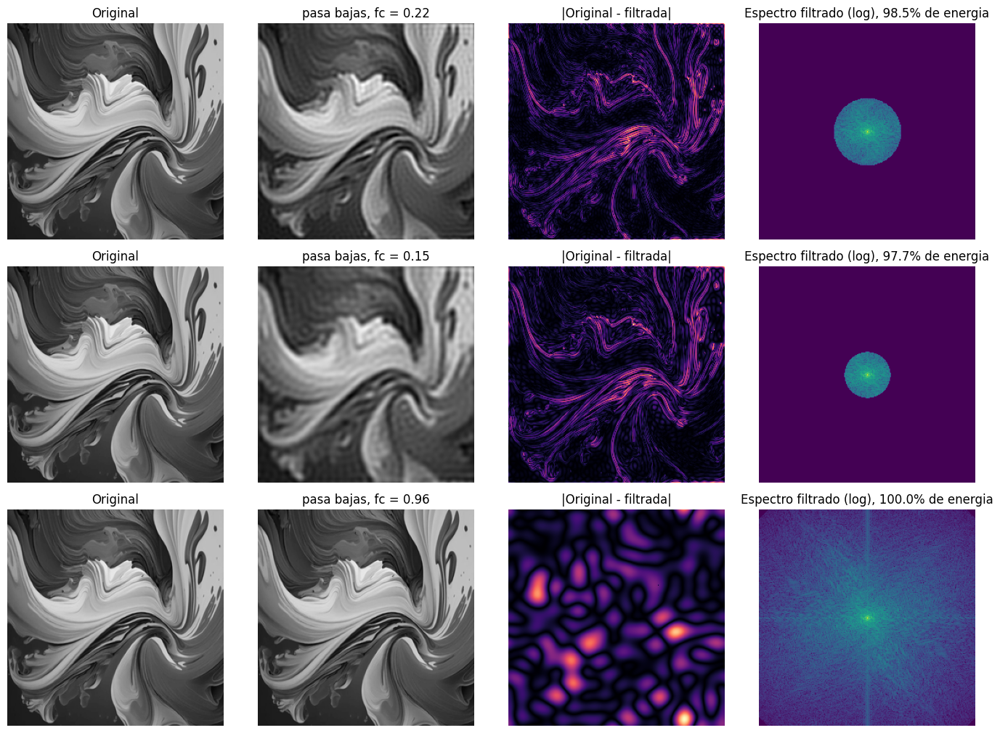

In [5]:
# frecuencias de corte pedidas en el enunciado
FC_BAJAS = [0.22, 0.15, 0.96]


# funcion que calcula la PSNR (en dB) entre la imagen original y la filtrada
def psnr(original, procesada):
    # error cuadratico medio
    mse = np.mean((original - procesada) ** 2)
    # PSNR infinita si no hay error
    return float("inf") if mse == 0 else 10 * np.log10(1.0 / mse)


# funcion que muestra y guarda la comparacion de una imagen con su version filtrada
def mostrar_filtro(nombre, img, fcs, funcion_filtro, funcion_mascara, etiqueta, normalizar=False):
    # espectro centrado de la imagen original (se calcula una sola vez)
    F = centrar_espectro(fft2_recursiva(img))
    # energia total del espectro
    energia_total = np.sum(np.abs(F) ** 2)
    # figura con una fila por frecuencia de corte y 4 columnas
    fig, ejes = plt.subplots(len(fcs), 4, figsize=(14, 3.4 * len(fcs)))
    # encabezado de la tabla de resultados numericos
    print(f"--- {nombre}: {etiqueta} ---")
    print(f"{'fc':>6} | {'energia conservada (%)':>22} | {'PSNR (dB)':>9}")
    # recorrido de cada frecuencia de corte
    for fila, fc in enumerate(fcs):
        # imagen filtrada con la FFT propia
        filtrada = funcion_filtro(img, fc)
        # mascara usada, para visualizar y calcular energia conservada
        mascara = funcion_mascara(img.shape, fc)
        # porcentaje de energia que sobrevive al filtro
        conservada = 100 * np.sum(np.abs(F * mascara) ** 2) / energia_total
        # resultados numericos de esta frecuencia de corte
        print(f"{fc:>6} | {conservada:>22.2f} | {psnr(img, np.clip(filtrada, 0, 1)):>9.2f}")
        # las imagenes pasa altas pueden tener negativos y se escalan solo para mostrarlas
        mostrada = normalizar_para_mostrar(filtrada) if normalizar else filtrada
        # columna 1: original
        ejes[fila, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
        ejes[fila, 0].set_title("Original")
        # columna 2: imagen filtrada
        ejes[fila, 1].imshow(mostrada, cmap="gray", vmin=0, vmax=1)
        ejes[fila, 1].set_title(f"{etiqueta}, fc = {fc}")
        # columna 3: diferencia absoluta con la original
        ejes[fila, 2].imshow(np.abs(img - filtrada), cmap="magma")
        ejes[fila, 2].set_title("|Original - filtrada|")
        # columna 4: espectro (escala log) despues de aplicar la mascara
        ejes[fila, 3].imshow(np.log1p(np.abs(F * mascara)), cmap="viridis")
        ejes[fila, 3].set_title(f"Espectro filtrado (log), {conservada:.1f}% de energia")
    # se quitan los ejes de todas las imagenes
    for ax in ejes.ravel():
        ax.axis("off")
    # ajuste de espacios y guardado para el reporte
    fig.tight_layout()
    fig.savefig(CARPETA_FIGURAS / f"{nombre}_{etiqueta.replace(' ', '_')}.png", dpi=200)
    plt.show()


# aplicacion del pasa bajas a todas las imagenes
for nombre, img in imagenes.items():
    mostrar_filtro(nombre, img, FC_BAJAS, filtro_pasabajas, mascara_pasabajas, "pasa bajas")

## Inciso 2. Filtro pasa altas (fc = 0.23, 0.11, 0.91)
El pasa altas elimina la componente DC, asi que el resultado tiene media cero. Para poder verlo se escala a [0, 1] solo para mostrarlo.

--- img1: pasa altas ---
    fc | energia conservada (%) | PSNR (dB)
  0.23 |                   1.48 |      5.68
  0.11 |                   3.77 |      5.96
  0.91 |                   0.00 |      5.36


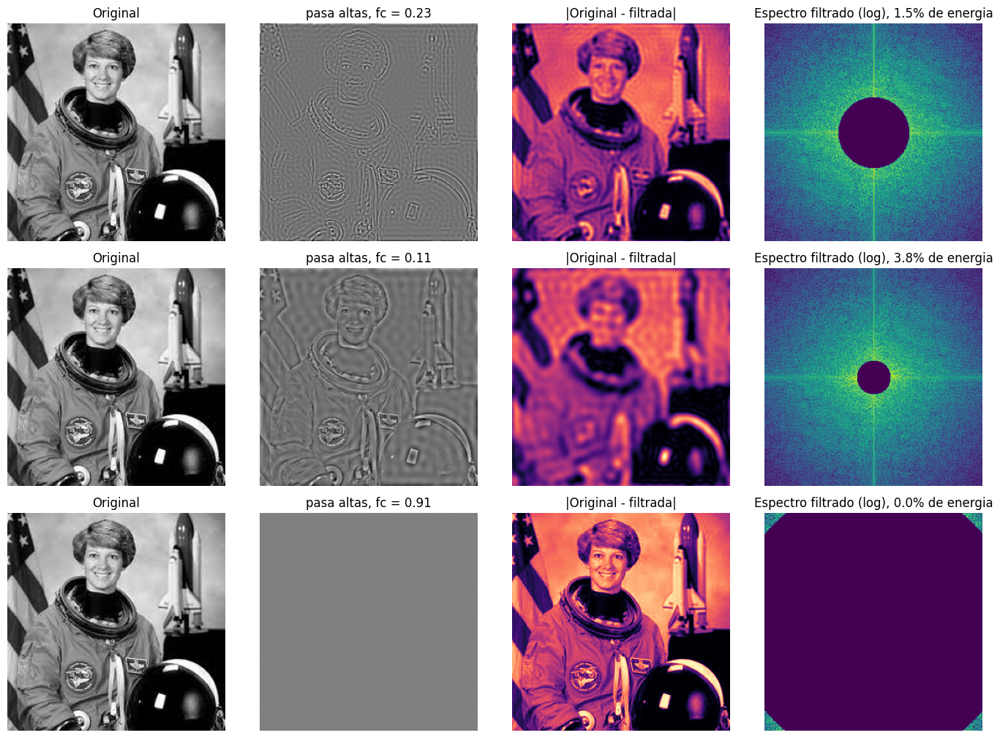

--- img3: pasa altas ---
    fc | energia conservada (%) | PSNR (dB)
  0.23 |                   0.60 |      4.84
  0.11 |                   1.68 |      5.02
  0.91 |                   0.00 |      4.65


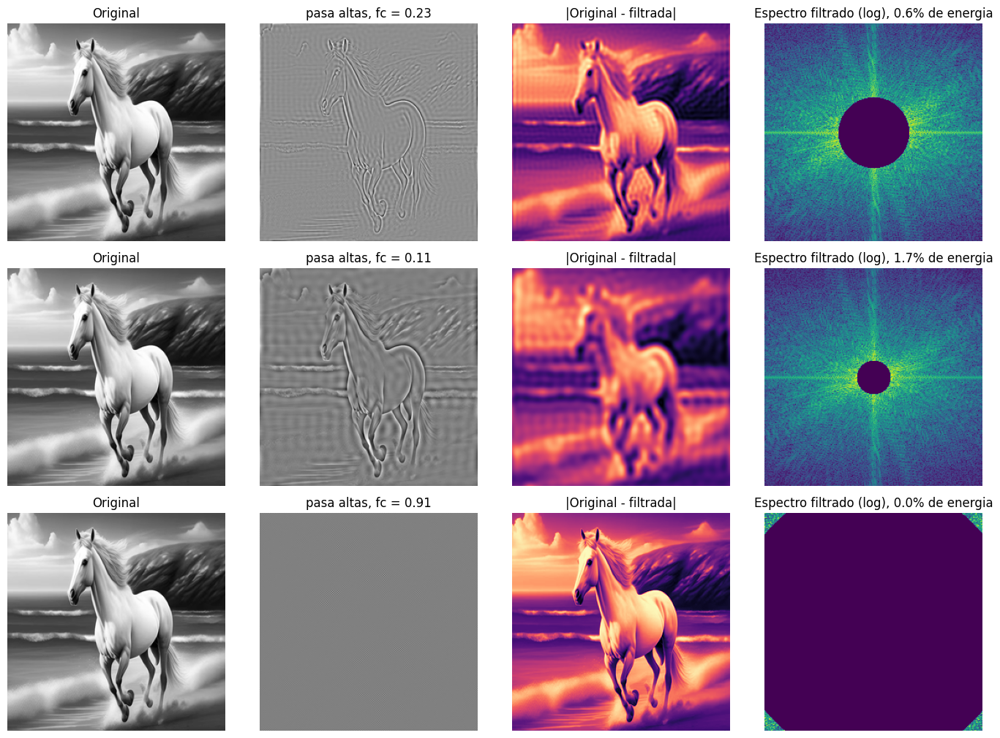

--- img4: pasa altas ---
    fc | energia conservada (%) | PSNR (dB)
  0.23 |                   1.39 |      7.26
  0.11 |                   3.17 |      7.50
  0.91 |                   0.00 |      6.90


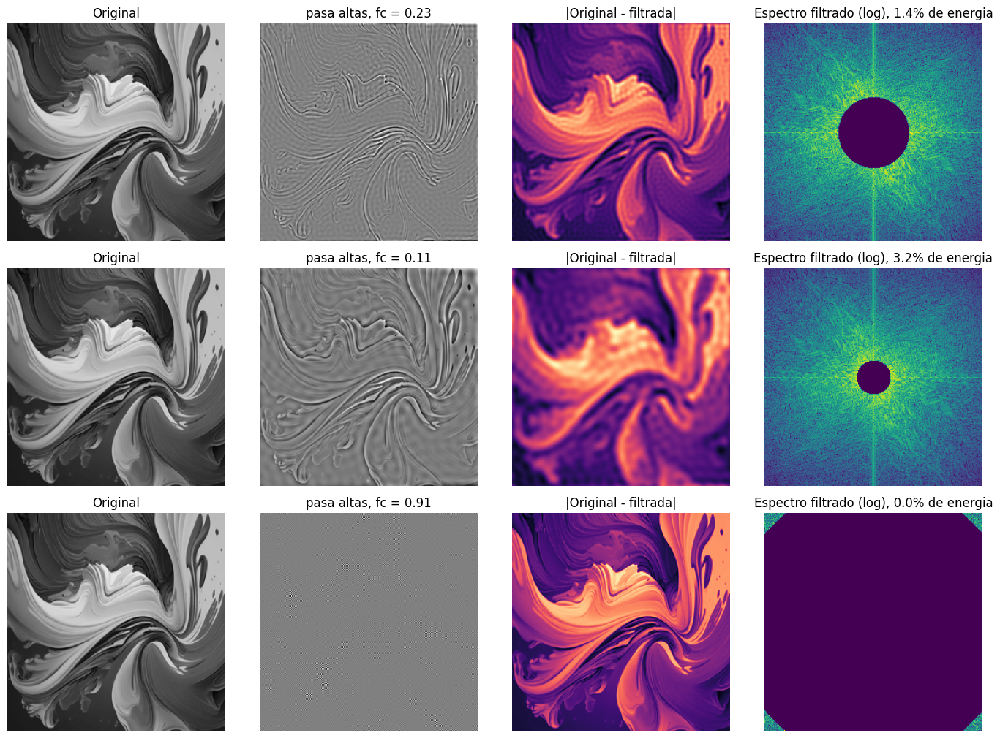

In [6]:
# frecuencias de corte pedidas en el enunciado
FC_ALTAS = [0.23, 0.11, 0.91]
# aplicacion del pasa altas a todas las imagenes (normalizar=True solo afecta la visualizacion)
for nombre, img in imagenes.items():
    mostrar_filtro(nombre, img, FC_ALTAS, filtro_pasaaltas, mascara_pasaaltas, "pasa altas", normalizar=True)

## Inciso 3. Blur Detection
**Metodo:** se calcula la fraccion de la energia espectral (sin la componente DC) que cae en altas frecuencias (`r > 0.1`). Una imagen nitida tiene bordes, es decir, energia en altas frecuencias; una desenfocada la pierde. Se compara con la varianza del Laplaciano como comprobacion independiente.

**Umbral:** el puntaje depende del contenido de la imagen, por eso el umbral por defecto (0.02) debe recalibrarse con las imagenes del proyecto.

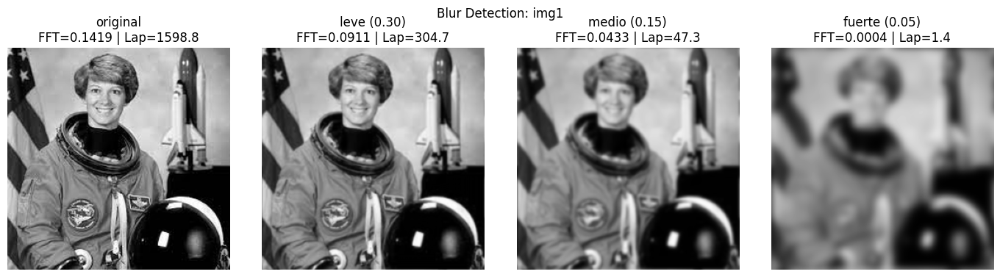

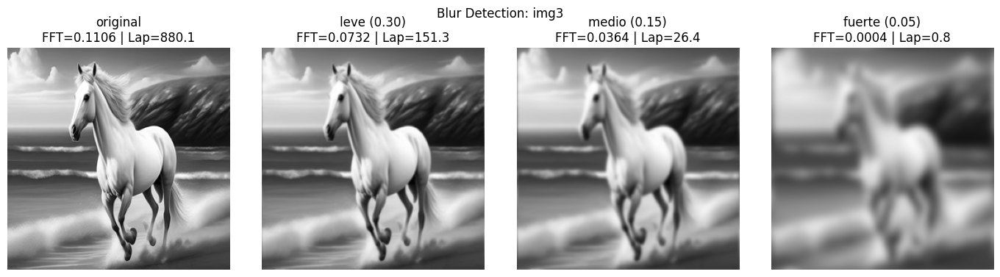

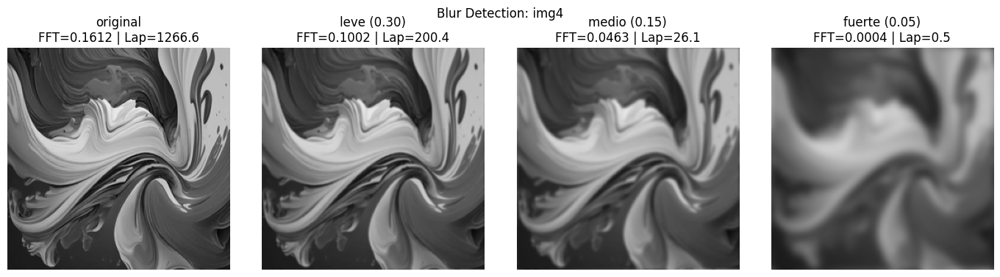

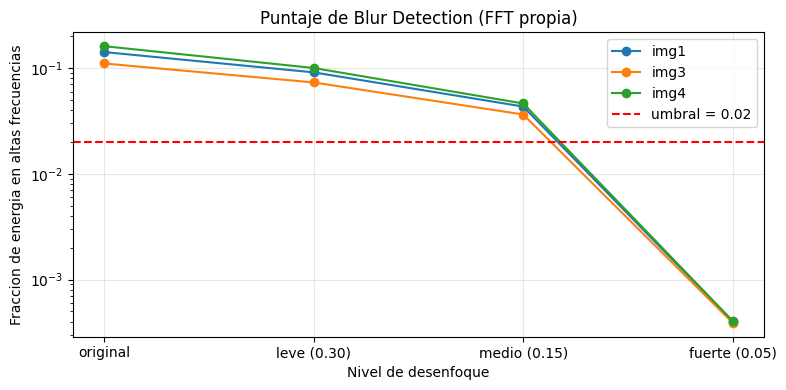

In [7]:
# umbral de decision (ver nota arriba); por debajo de este puntaje se considera desenfocada
UMBRAL = 0.02
# niveles de desenfoque artificial para validar el detector (fc del pasa bajas gaussiano; None = original)
NIVELES = [None, 0.30, 0.15, 0.05]
# nombres de cada nivel para las graficas
ETIQUETAS = ["original", "leve (0.30)", "medio (0.15)", "fuerte (0.05)"]
# diccionario donde se guardan los puntajes para graficarlos despues
puntajes = {}
# recorrido de cada imagen
for nombre, img in imagenes.items():
    # version de la imagen para cada nivel de desenfoque
    versiones = [img if fc is None else desenfoque_gaussiano(img, fc) for fc in NIVELES]
    # puntaje FFT de cada version
    puntajes[nombre] = [puntaje_blur_fft(v) for v in versiones]
    # figura con una columna por nivel
    fig, ejes = plt.subplots(1, len(NIVELES), figsize=(14, 3.8))
    # recorrido de cada version
    for ax, v, etq, p in zip(ejes, versiones, ETIQUETAS, puntajes[nombre]):
        # imagen y su puntaje en el titulo
        ax.imshow(v, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{etq}\nFFT={p:.4f} | Lap={varianza_laplaciano(v) * 255**2:.1f}")
        ax.axis("off")
    # guardado para el reporte
    fig.suptitle(f"Blur Detection: {nombre}")
    fig.tight_layout()
    fig.savefig(CARPETA_FIGURAS / f"{nombre}_blur_niveles.png", dpi=200)
    plt.show()
# grafica de puntaje contra nivel de desenfoque para todas las imagenes
plt.figure(figsize=(8, 4))
# una curva por imagen
for nombre, valores in puntajes.items():
    plt.plot(ETIQUETAS, valores, "o-", label=nombre)
# linea del umbral de decision
plt.axhline(UMBRAL, color="r", linestyle="--", label=f"umbral = {UMBRAL}")
# escala logaritmica porque los puntajes cambian en ordenes de magnitud
plt.yscale("log")
plt.xlabel("Nivel de desenfoque")
plt.ylabel("Fraccion de energia en altas frecuencias")
plt.title("Puntaje de Blur Detection (FFT propia)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "blur_puntajes.png", dpi=200)
plt.show()

In [8]:
# veredicto del detector sobre las imagenes originales del proyecto
print(f"{'imagen':<20} | {'puntaje FFT':>11} | {'var. Laplaciano':>15} | veredicto")
# recorrido de cada imagen
for nombre, img in imagenes.items():
    # resultado del detector con el umbral definido
    r = detectar_desenfoque(img, UMBRAL)
    # impresion de la fila
    print(f"{nombre:<20} | {r['puntaje_fft']:>11.4f} | {r['laplaciano'] * 255**2:>15.1f} | {'DESENFOCADA' if r['desenfocada'] else 'nitida'}")
# prueba: en cada imagen el puntaje debe decrecer al aumentar el desenfoque
for nombre, valores in puntajes.items():
    # cada nivel debe tener menos energia en altas frecuencias que el anterior
    assert all(a > b for a, b in zip(valores, valores[1:])), f"puntaje no decreciente en {nombre}"
# prueba: el desenfoque fuerte debe quedar por debajo del umbral
for nombre, valores in puntajes.items():
    assert valores[-1] < UMBRAL, f"el desenfoque fuerte no se detecta en {nombre}"
# mensaje de exito
print("Pruebas de Blur Detection correctas")

imagen               | puntaje FFT | var. Laplaciano | veredicto
img1                 |      0.1419 |          1598.8 | nitida
img3                 |      0.1106 |           880.1 | nitida
img4                 |      0.1612 |          1266.6 | nitida
Pruebas de Blur Detection correctas
